In [1]:
import pandas as pd
import numpy as np

In [2]:
file_path = 'Assessment_-_Data_Scientist.xlsx'

In [3]:
application = pd.read_excel(file_path , sheet_name= "Application Data")

In [4]:
performance = pd.read_excel(file_path , sheet_name="Loan Performance")

In [5]:
print("Application Dataset: ", application.shape)
print("Loan Performance Dataset: ", performance.shape)

Application Dataset:  (647, 31)
Loan Performance Dataset:  (1285, 2)


In [6]:
print("\nApplication Columns",application.columns.tolist())
print("\nLoan Performance Columns",performance.columns.tolist())


Application Columns ['customer_id', 'amount_requested', 'birth_date', 'status', 'residence_rent_or_own', 'monthly_rent_amount', 'bank_account_direct_deposit', 'application_when', 'loan_duration', 'payment_ach', 'num_payments', 'payment_amount', 'amount_approved', 'duration_approved', 'payment_amount_approved', 'address_zip', 'email', 'bank_routing_number', 'email_duration', 'residence_duration', 'bank_account_duration', 'payment_frequency', 'home_phone_type', 'other_phone_type', 'how_use_money', 'monthly_income_amount', 'raw_l2c_score', 'raw_FICO_telecom', 'raw_FICO_retail', 'raw_FICO_bank_card', 'raw_FICO_money']

Loan Performance Columns ['idLoan', 'flgGood']


In [7]:
print("\nApplication data : ")
display(application.head())
print("\nLoan Performance data : ")
display(performance.head())


Application data : 


,customer_id,amount_requested,birth_date,status,residence_rent_or_own,monthly_rent_amount,bank_account_direct_deposit,application_when,loan_duration,payment_ach,...,payment_frequency,home_phone_type,other_phone_type,how_use_money,monthly_income_amount,raw_l2c_score,raw_FICO_telecom,raw_FICO_retail,raw_FICO_bank_card,raw_FICO_money
0,9ece67d6c5,500,1991-08-21,Approved,True,0,True,2010-10-16 14:06:05,3,True,...,Semi-monthly,Mobile,NaN,Other,1560,614,574,600,656,561
1,5c2c402094,500,1990-07-24,Approved,True,0,False,2010-10-17 13:01:53,6,True,...,Bi-weekly,Mobile,NaN,Other,900,708,501,550,651,563
2,e6254cad30,400,1980-09-13,Approved,True,620,True,2010-10-17 19:52:34,6,True,...,Bi-weekly,Mobile,NaN,Other,1434,687,522,561,661,598
3,49fb42f51d,500,1976-09-10,Approved,False,785,False,2010-10-18 07:05:00,4,True,...,Bi-weekly,Mobile,NaN,Other,1600,616,560,552,634,591
4,195fbe5739,300,1979-12-01,Approved,True,700,True,2010-10-19 10:58:40,4,True,...,Bi-weekly,Mobile,Home,Other,1360,681,603,654,659,636



Loan Performance data : 


,idLoan,flgGood
0,0DBA6B011D-01,Bad
1,96ACBBA7ED-01,Bad
2,289421D82A-01,Bad
3,9ECE67D6C5-01,Good
4,5C2C402094-01,Bad


In [8]:

application["customer_id"] = (
    application["customer_id"].astype("string").str.strip().str.lower()
)

performance["idLoan"] = (
    performance["idLoan"].astype("string").str.strip().str.upper()
)

performance["customer_id"] = (
    performance["idLoan"].str.split("-").str[0].str.lower()
)


application_ids = set(application["customer_id"].dropna())
performance_ids = set(performance["customer_id"].dropna())

matched_ids = application_ids & performance_ids

print("Unique application IDs:", len(application_ids))
print("Unique performance IDs:", len(performance_ids))
print("Matched customer IDs:", len(matched_ids))
print("Unmatched application IDs:", len(application_ids - performance_ids))

print(
    "\nLoan records with repeated customer IDs:",
    performance["customer_id"].duplicated().sum()
)


Unique application IDs: 647
Unique performance IDs: 1269
Matched customer IDs: 640
Unmatched application IDs: 7

Loan records with repeated customer IDs: 16


In [9]:

print("Missing application values:")
print(
    application.isnull().sum()
    .sort_values(ascending=False)
    .head(15)
)

print("\nMissing performance values:")
print(performance.isnull().sum())


print(
    "\nDuplicate application rows:",
    application.duplicated().sum()
)

print(
    "Duplicate loan IDs:",
    performance["idLoan"].duplicated().sum()
)


print("\nLoan outcome counts:")
print(performance["flgGood"].value_counts(dropna=False))

print("\nLoan outcome percentages:")
print(
    (performance["flgGood"].value_counts(normalize=True) * 100)
    .round(2)
)


Missing application values:
other_phone_type               285
payment_amount_approved         20
how_use_money                    2
bank_account_duration            1
status                           0
amount_requested                 0
customer_id                      0
bank_account_direct_deposit      0
application_when                 0
payment_ach                      0
loan_duration                    0
num_payments                     0
residence_rent_or_own            0
monthly_rent_amount              0
birth_date                       0
dtype: int64

Missing performance values:
idLoan         0
flgGood        0
customer_id    0
dtype: int64

Duplicate application rows: 0
Duplicate loan IDs: 0

Loan outcome counts:
flgGood
Good    769
Bad     516
Name: count, dtype: int64

Loan outcome percentages:
flgGood
Good    59.84
Bad     40.16
Name: proportion, dtype: float64


In [10]:


performance["idLoan"] = (
    performance["idLoan"].astype("string").str.strip().str.upper()
)


performance["customer_id"] = (
    performance["idLoan"].str.split("-").str[0].str.lower()
)

application["customer_id"] = (
    application["customer_id"].astype("string").str.strip().str.lower()
)


analysis_df = performance.merge(
    application,
    on="customer_id",
    how="inner",
    validate="many_to_one"
)

print("Joined dataset shape:", analysis_df.shape)
print("Unique customers:", analysis_df["customer_id"].nunique())
print("\nLoan outcomes:")
print(analysis_df["flgGood"].value_counts())


bad_rate = (analysis_df["flgGood"] == "Bad").mean() * 100
print(f"\nBad-loan rate in matched records: {bad_rate:.2f}%")


Joined dataset shape: (656, 33)
Unique customers: 640

Loan outcomes:
flgGood
Bad     354
Good    302
Name: count, dtype: int64

Bad-loan rate in matched records: 53.96%


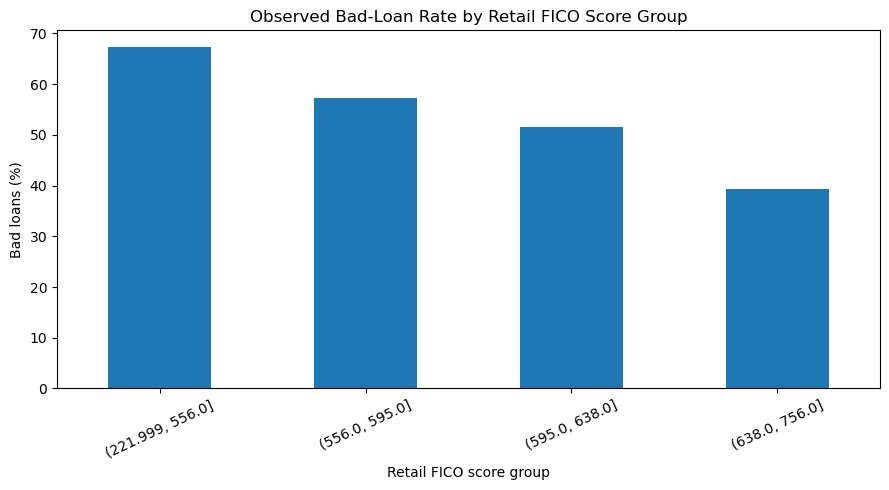

In [11]:

import matplotlib.pyplot as plt
import pandas as pd


scored = analysis_df[
    analysis_df["flgGood"].isin(["Good", "Bad"])
].copy()

score_col = "raw_FICO_retail"


scored["score_group"] = pd.qcut(
    scored[score_col],
    q=4,
    duplicates="drop"
)


risk_by_score = (
    scored.groupby("score_group", observed=True)["flgGood"]
    .apply(lambda x: (x == "Bad").mean() * 100)
)


ax = risk_by_score.plot(kind="bar", figsize=(9, 5))

ax.set_title("Observed Bad-Loan Rate by Retail FICO Score Group")
ax.set_xlabel("Retail FICO score group")
ax.set_ylabel("Bad loans (%)")
ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()


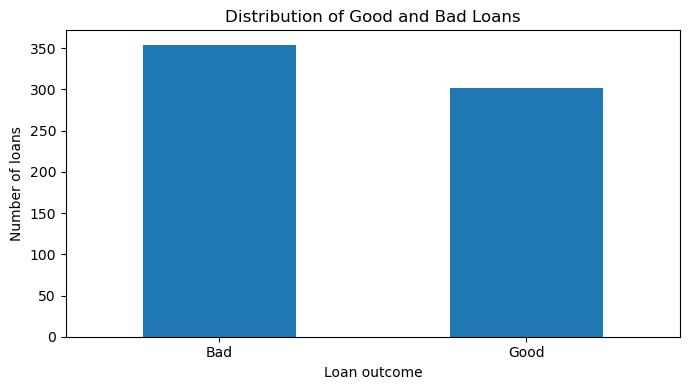

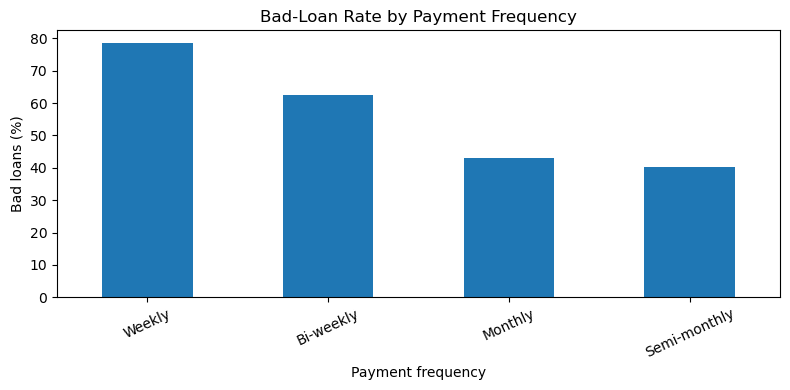

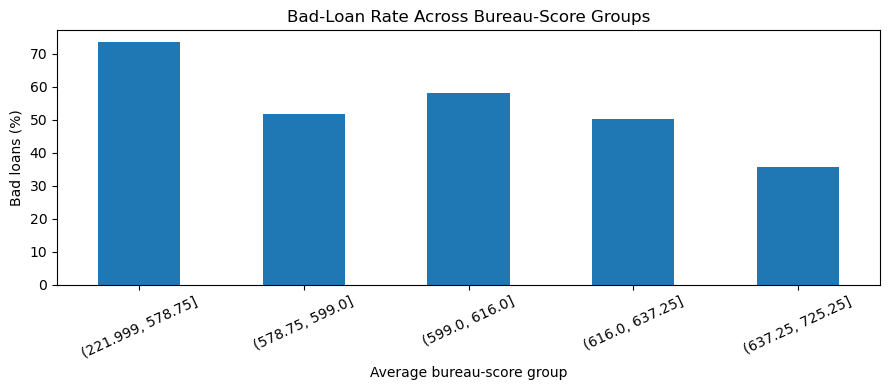

In [12]:

import matplotlib.pyplot as plt
import pandas as pd

eda = analysis_df[
    analysis_df["flgGood"].isin(["Good", "Bad"])
].copy()


outcome_counts = eda["flgGood"].value_counts()

outcome_counts.plot(kind="bar", figsize=(7, 4))
plt.title("Distribution of Good and Bad Loans")
plt.xlabel("Loan outcome")
plt.ylabel("Number of loans")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


pay_risk = (
    eda.groupby("payment_frequency", dropna=False)["flgGood"]
    .apply(lambda s: (s == "Bad").mean() * 100)
    .sort_values(ascending=False)
)

pay_risk.plot(kind="bar", figsize=(8, 4))
plt.title("Bad-Loan Rate by Payment Frequency")
plt.xlabel("Payment frequency")
plt.ylabel("Bad loans (%)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


score_cols = [
    "raw_FICO_telecom",
    "raw_FICO_retail",
    "raw_FICO_bank_card",
    "raw_FICO_money"
]

eda["average_bureau_score"] = eda[score_cols].mean(axis=1)

eda["score_group"] = pd.qcut(
    eda["average_bureau_score"],
    q=5,
    duplicates="drop"
)

score_risk = (
    eda.groupby("score_group", observed=True)["flgGood"]
    .apply(lambda s: (s == "Bad").mean() * 100)
)

score_risk.plot(kind="bar", figsize=(9, 4))
plt.title("Bad-Loan Rate Across Bureau-Score Groups")
plt.xlabel("Average bureau-score group")
plt.ylabel("Bad loans (%)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


In [13]:

model_df = analysis_df[
    analysis_df["flgGood"].isin(["Good", "Bad"])
].copy()

model_df["bad_loan"] = (
    model_df["flgGood"] == "Bad"
).astype(int)


candidate_features = [
    "raw_FICO_telecom",
    "raw_FICO_retail",
    "raw_FICO_bank_card",
    "raw_FICO_money",
    "monthly_income_amount",
    "amount_requested",
    "loan_duration",
    "num_payments",
    "payment_frequency",
    "residence_rent_or_own",
    "bank_account_direct_deposit",
    "payment_ach",
    "email_duration",
    "residence_duration",
    "bank_account_duration"
]

X = model_df[candidate_features].copy()
y = model_df["bad_loan"]

print("Feature matrix:", X.shape)
print("Target distribution:")
print(y.value_counts())
print("\nBad-loan rate:", round(y.mean() * 100, 2), "%")


Feature matrix: (656, 15)
Target distribution:
bad_loan
1    354
0    302
Name: count, dtype: int64

Bad-loan rate: 53.96 %


In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)

# --------------------------------------------------
# 1. Prepare the identifiers and match first loans
# --------------------------------------------------
app = application.copy()
loans = performance.copy()

app["customer_id"] = (
    app["customer_id"].astype("string").str.strip().str.lower()
)

loans["idLoan"] = (
    loans["idLoan"].astype("string").str.strip().str.upper()
)

# Keep first-loan records only
first_loans = loans[
    loans["idLoan"].str.endswith("-01", na=False)
].copy()

first_loans["customer_id"] = (
    first_loans["idLoan"].str[:10].str.lower()
)

# Do not silently multiply rows if application IDs are duplicated
app = app.dropna(subset=["customer_id"]).copy()

if app["customer_id"].duplicated().any():
    raise ValueError("Duplicate application IDs need investigation.")

data = first_loans.merge(
    app,
    on="customer_id",
    how="inner",
    validate="one_to_one"
)

# Define the target: 1 = Bad, 0 = Good
data["bad_loan"] = data["flgGood"].map(
    {"Bad": 1, "Good": 0}
)

data["application_when"] = pd.to_datetime(
    data["application_when"], errors="coerce"
)

# Derive age at the time of application
data["birth_date"] = pd.to_datetime(
    data["birth_date"], errors="coerce"
)

data["age_at_application"] = (
    (data["application_when"] - data["birth_date"])
    .dt.days / 365.25
)

data = data.dropna(
    subset=["bad_loan", "application_when"]
).copy()

print("Matched first-loan records:", len(data))
print("Unique customers:", data["customer_id"].nunique())
print("Bad-loan rate:", round(data["bad_loan"].mean() * 100, 2), "%")

# --------------------------------------------------
# 2. Select candidate features
# --------------------------------------------------
numeric_features = [
    "raw_FICO_telecom",
    "raw_FICO_retail",
    "raw_FICO_bank_card",
    "raw_FICO_money",
    "monthly_income_amount",
    "amount_requested",
    "loan_duration",
    "num_payments",
    "age_at_application"
]

categorical_features = [
    "payment_frequency",
    "residence_rent_or_own",
    "bank_account_direct_deposit",
    "payment_ach",
    "email_duration",
    "residence_duration",
    "bank_account_duration",
    "how_use_money"
]

features = numeric_features + categorical_features

# --------------------------------------------------
# 3. Split by time, not randomly
# --------------------------------------------------
train = data[
    data["application_when"] < "2011-03-01"
].copy()

test = data[
    data["application_when"] >= "2011-03-01"
].copy()

if train.empty or test.empty:
    raise ValueError(
        "Check application dates and choose a valid time cutoff."
    )

X_train = train[features]
y_train = train["bad_loan"].astype(int)

X_test = test[features]
y_test = test["bad_loan"].astype(int)

print("Training records:", len(train))
print("Test records:", len(test))

# --------------------------------------------------
# 4. Prepare numeric and categorical variables
# --------------------------------------------------
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight=None
    ))
])

# --------------------------------------------------
# 5. Train and evaluate
# --------------------------------------------------
model.fit(X_train, y_train)

probabilities = model.predict_proba(X_test)[:, 1]
predictions = (probabilities >= 0.5).astype(int)

print("\nROC-AUC:", round(
    roc_auc_score(y_test, probabilities), 3
))

print("Accuracy:", round(
    accuracy_score(y_test, predictions), 3
))

print("Precision:", round(
    precision_score(y_test, predictions, zero_division=0), 3
))

print("Recall:", round(
    recall_score(y_test, predictions, zero_division=0), 3
))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, predictions))

print("\nClassification report:")
print(classification_report(
    y_test,
    predictions,
    target_names=["Good loan", "Bad loan"],
    zero_division=0
))


Matched first-loan records: 640
Unique customers: 640
Bad-loan rate: 54.84 %
Training records: 392
Test records: 248

ROC-AUC: 0.627
Accuracy: 0.565
Precision: 0.524
Recall: 0.846

Confusion matrix:
[[41 90]
 [18 99]]

Classification report:
              precision    recall  f1-score   support

   Good loan       0.69      0.31      0.43       131
    Bad loan       0.52      0.85      0.65       117

    accuracy                           0.56       248
   macro avg       0.61      0.58      0.54       248
weighted avg       0.61      0.56      0.53       248



In [15]:

from sklearn.metrics import confusion_matrix
import pandas as pd

results = []

for threshold in [0.30, 0.40, 0.50, 0.60, 0.70]:
    predicted_bad = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predicted_bad,
        labels=[0, 1]
    ).ravel()

    results.append({
        "Threshold": threshold,
        "Bad loans caught": tp,
        "Bad loans missed": fn,
        "Good loans flagged": fp,
        "Good loans identified": tn,
        "Bad-loan recall": tp / (tp + fn),
        "Bad-loan precision": tp / (tp + fp)
    })

threshold_results = pd.DataFrame(results)

print(
    threshold_results.round(3).to_string(index=False)
)


 Threshold  Bad loans caught  Bad loans missed  Good loans flagged  Good loans identified  Bad-loan recall  Bad-loan precision
       0.3               115                 2                 124                      7            0.983               0.481
       0.4               109                 8                 111                     20            0.932               0.495
       0.5                99                18                  90                     41            0.846               0.524
       0.6                78                39                  65                     66            0.667               0.545
       0.7                60                57                  42                     89            0.513               0.588


In [16]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, accuracy_score

# Train a Random Forest using the same data split
rf_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=10,
        class_weight=None,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)

# Probabilities of a Bad loan
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

# Compare models at threshold 0.50
lr_probabilities = probabilities

comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "ROC-AUC": roc_auc_score(y_test, lr_probabilities),
        "Accuracy": accuracy_score(
            y_test, (lr_probabilities >= 0.5).astype(int)
        )
    },
    {
        "Model": "Random Forest",
        "ROC-AUC": roc_auc_score(y_test, rf_probabilities),
        "Accuracy": accuracy_score(
            y_test, (rf_probabilities >= 0.5).astype(int)
        )
    }
])

print(comparison.round(3).to_string(index=False))


              Model  ROC-AUC  Accuracy
Logistic Regression    0.627     0.565
      Random Forest    0.628     0.548


In [17]:

# Evaluate approval strategies on the held-out test set.
# Lower predicted probability means lower estimated bad-loan risk.

approval_eval = test[
    ["customer_id", "bad_loan"]
].copy()

approval_eval["predicted_bad_risk"] = probabilities

approval_eval = approval_eval.sort_values(
    "predicted_bad_risk",
    ascending=True
).reset_index(drop=True)

overall_bad_rate = approval_eval["bad_loan"].mean()

print(f"Overall test bad-loan rate: {overall_bad_rate:.1%}\n")

results = []

for approval_share in [0.20, 0.30, 0.40, 0.60, 1.00]:
    n_approved = round(len(approval_eval) * approval_share)

    selected = approval_eval.iloc[:n_approved]

    results.append({
        "Share approved": f"{approval_share:.0%}",
        "Applicants selected": n_approved,
        "Observed bad loans": int(selected["bad_loan"].sum()),
        "Bad-loan rate among selected": selected["bad_loan"].mean(),
        "Good-loan rate among selected": 1 - selected["bad_loan"].mean()
    })

approval_results = pd.DataFrame(results)

print(approval_results.to_string(
    index=False,
    formatters={
        "Bad-loan rate among selected": "{:.1%}".format,
        "Good-loan rate among selected": "{:.1%}".format
    }
))


Overall test bad-loan rate: 47.2%

Share approved  Applicants selected  Observed bad loans Bad-loan rate among selected Good-loan rate among selected
           20%                   50                  16                        32.0%                         68.0%
           30%                   74                  22                        29.7%                         70.3%
           40%                   99                  38                        38.4%                         61.6%
           60%                  149                  60                        40.3%                         59.7%
          100%                  248                 117                        47.2%                         52.8%


In [18]:

# Get the transformed feature names
feature_names = (
    model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Extract Logistic Regression coefficients
coefficients = (
    model.named_steps["classifier"].coef_[0]
)

importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Odds ratio": np.exp(coefficients)
})

# Sort by coefficient to see the strongest positive
# and negative associations with predicted Bad-loan risk
importance = importance.sort_values(
    "Coefficient",
    ascending=False
)

print("Features associated with higher predicted risk:")
print(importance.head(10).round(3).to_string(index=False))

print("\nFeatures associated with lower predicted risk:")
print(
    importance.tail(10)
    .sort_values("Coefficient")
    .round(3)
    .to_string(index=False)
)


Features associated with higher predicted risk:
                                       Feature  Coefficient  Odds ratio
         categorical__payment_frequency_Weekly        0.912       2.489
    categorical__how_use_money_Bills (General)        0.652       1.919
    categorical__how_use_money_Bills (Medical)        0.475       1.608
       categorical__how_use_money_Bills (Auto)        0.393       1.481
   categorical__residence_duration_7-12 months        0.373       1.452
              categorical__how_use_money_Bills        0.333       1.396
          categorical__how_use_money_Won't say        0.284       1.328
      categorical__payment_frequency_Bi-weekly        0.274       1.316
categorical__bank_account_direct_deposit_False        0.226       1.254
                     numeric__amount_requested        0.173       1.189

Features associated with lower predicted risk:
                                                  Feature  Coefficient  Odds ratio
              categorical__pa

In [19]:

# Build a test-set table using the existing predictions
risk_eval = pd.DataFrame({
    "actual_bad": np.asarray(y_test),
    "predicted_risk": probabilities
})

# Rank applicants into ten groups, from lowest to highest risk
risk_eval["risk_decile"] = pd.qcut(
    risk_eval["predicted_risk"].rank(method="first"),
    q=10,
    labels=False
) + 1

decile_results = (
    risk_eval.groupby("risk_decile")
    .agg(
        applicants=("actual_bad", "size"),
        average_predicted_risk=("predicted_risk", "mean"),
        observed_bad_rate=("actual_bad", "mean")
    )
    .reset_index()
)

# Convert rates to percentages
decile_results["average_predicted_risk"] *= 100
decile_results["observed_bad_rate"] *= 100

print(decile_results.round(2).to_string(index=False))


 risk_decile  applicants  average_predicted_risk  observed_bad_rate
           1          25                   31.35              32.00
           2          25                   44.08              32.00
           3          25                   51.17              24.00
           4          24                   57.07              66.67
           5          25                   61.46              40.00
           6          25                   67.17              48.00
           7          24                   72.27              54.17
           8          25                   76.06              60.00
           9          25                   80.61              48.00
          10          25                   86.13              68.00
